In [1]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import box
import sys
import numpy as np
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt

# Import Necessary Clustering Functions

In [2]:
sys.path.append('../src/nlr_ghe_screen/clustering/')
from seed_clustering import (
    find_seed_centroids_single
)
from construct_clusters import (
    build_clusters,
    create_cluster_subgraph,
)
from distance_matrices import (
    road_network_distance_to_centroid,
    euclidian_distance_to_centroid
)
from load_profile_processing import (
    get_building_load_profiles
)
from milp import (
    solve_cluster
)

sys.path.append('../src/nlr_ghe_screen/api/')
from building_footprint_api import (
    get_overture_footprints,
    get_ornl_footprints,
    join_ornl_overture_buildings
    
)
from osmnx_api import (
    get_road_network,
    plot_network_graph
)

# Download Necessary Building and Road Network Data

In [3]:
TEST_BBOX = (47.58, -122.36, 47.61, -122.31) # xmin, ymin, xmax, ymax
south, west, north, east = TEST_BBOX

In [4]:
ghe_locations = gpd.read_file("../src/exports/ghe_locations.geojson")
geom_box = box(west, south, east, north)
cropped_ghes = gpd.clip(ghe_locations, geom_box)
cropped_ghes = cropped_ghes.to_crs(cropped_ghes.estimate_utm_crs())

In [5]:
overture_buildings = get_overture_footprints(bbox=TEST_BBOX)
ornl_buildings = get_ornl_footprints(bbox=TEST_BBOX)


---------------------------
Retrieving Overture Maps Data
Success - Data retrieved
---------------------------

---------------------------
Retrieving ORNL Structure Data
total features: 2898
2000/2898
2898/2898
Success - Data retrieved
---------------------------


In [6]:
ornl_buildings = ornl_buildings.to_crs(cropped_ghes.crs)
overture_buildings = overture_buildings.to_crs(cropped_ghes.crs)

In [7]:
buildings_joined = join_ornl_overture_buildings(
    ornl_data=ornl_buildings,
    overture_data=overture_buildings
)

In [9]:
network = get_road_network(bbox=TEST_BBOX)


---------------------------
Post - Networkx road network request
Success - Query Received
---------------------------


In [10]:
network = network.to_undirected()
network.is_directed()

False

# Aggregate Cluster Seeds + Nearby Buildings

In [11]:
cropped_ghes, seed_centroids = find_seed_centroids_single(
    ghe_locations=cropped_ghes,
)

In [12]:
des_clusters = build_clusters(
    seed_centroids=seed_centroids,
    building_data=buildings_joined,
    G=network,
    max_distance=500,
)

In [13]:
idx = 250
cluster = des_clusters[des_clusters['cluster'] == idx]

m = cropped_ghes[cropped_ghes['cluster'] == idx].explore(color='green')
seed_centroids[seed_centroids['cluster'] == idx].explore(m=m, color='red')
cluster.explore(m=m, color='blue')

In [16]:
cluster_seed_centroid = seed_centroids.loc[seed_centroids['cluster'] == idx, 'geometry'].item()
cluster['centroid_distance'] = road_network_distance_to_centroid(
    buildings_df=cluster,
    centroid=cluster_seed_centroid,
    G=network,
    max_distance=500
)

# Download Representative Load Profile Curves

In [17]:
building_types = cluster['comstock_type'].tolist()
building_sizes = cluster['sqfeet'].tolist()
building_distances = cluster['centroid_distance'].tolist()

In [18]:
building_sources = [
    'restock' if building_type == "Multi-Family with 5+ Units" else 'comstock'
    for building_type in building_types
]

In [19]:
frames = get_building_load_profiles(
    building_types=building_types,
    building_sizes=building_sizes,
    building_sources=building_sources,
    state='WA',
)

Metadata csv already exists. Skipping creation. Delete metadata/restock/amy2018_release_1-WA-All-Multi-Family with 5+ Units-All-0-selected_metadata.csv if you want to save again.
Error: No Multi-Family with 5+ Units buildings within 40.0% of 33830 sqft found in state='WA'; increase sqft_tolerance_pct.
Metadata csv already exists. Skipping creation. Delete metadata/comstock/release_3-WA-All-Warehouse-All-0-selected_metadata.csv if you want to save again.


/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/_base.py:229: DtypeWarning: Columns (0: in.misc_well_pump) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)
/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/_base.py:229: DtypeWarning: Columns (0: in.economizer_damper_stuck_fault_timing) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)
/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/building_condition.py:129: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  working = metadata.assign(_building_condition_eui=eui).dropna(subset=["_b

Metadata csv already exists. Skipping creation. Delete metadata/comstock/release_3-WA-All-Warehouse-All-27-selected_metadata.csv if you want to save again.


/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/_base.py:229: DtypeWarning: Columns (0: in.economizer_damper_stuck_fault_timing) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


Number of workers: 16


100%|██████████| 1/1 [00:00<00:00, 4832.15it/s]


... (109 outputs left out)

/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/_base.py:229: DtypeWarning: Columns (0: in.misc_well_pump) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)
/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/_base.py:229: DtypeWarning: Columns (0: in.misc_well_pump) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


Error: No Multi-Family with 5+ Units buildings within 40.0% of 22690 sqft found in state='WA'; increase sqft_tolerance_pct.
Metadata csv already exists. Skipping creation. Delete metadata/restock/amy2018_release_1-WA-All-Multi-Family with 5+ Units-All-0-selected_metadata.csv if you want to save again.
Error: No Multi-Family with 5+ Units buildings within 40.0% of 26970 sqft found in state='WA'; increase sqft_tolerance_pct.
Metadata csv already exists. Skipping creation. Delete metadata/restock/amy2018_release_1-WA-All-Multi-Family with 5+ Units-All-0-selected_metadata.csv if you want to save again.


/Users/jbarrows/Desktop/NLR-GHE-Screen/building-energy-profiles/src/building_energy_profiles/_base.py:229: DtypeWarning: Columns (0: in.misc_well_pump) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


Error: No Multi-Family with 5+ Units buildings within 40.0% of 19540 sqft found in state='WA'; increase sqft_tolerance_pct.


In [20]:
for frame in frames:
    print(frame.attrs)

{'bldg_id': 2475, 'representative_sqft': 10000.0, 'scale': 1.246, 'upgrade': '27', 'bldg_type': 'Warehouse'}
{'bldg_id': 235349, 'representative_sqft': 6348.0, 'scale': 1.2570888468809074, 'upgrade': '0', 'bldg_type': 'Multi-Family with 5+ Units'}
{'bldg_id': 889, 'representative_sqft': 2000.0, 'scale': 0.765, 'upgrade': '27', 'bldg_type': 'Warehouse'}
{'bldg_id': 82629, 'representative_sqft': 3171.0, 'scale': 1.554714601072217, 'upgrade': '0', 'bldg_type': 'Multi-Family with 5+ Units'}
{'bldg_id': 2475, 'representative_sqft': 10000.0, 'scale': 0.959, 'upgrade': '27', 'bldg_type': 'Warehouse'}
{'bldg_id': 16232, 'representative_sqft': 21000.0, 'scale': 0.7957142857142857, 'upgrade': '27', 'bldg_type': 'Warehouse'}
{'bldg_id': 2480, 'representative_sqft': 67000.0, 'scale': 1.2692537313432837, 'upgrade': '27', 'bldg_type': 'Warehouse'}
{'bldg_id': 6458, 'representative_sqft': 10000.0, 'scale': 1.632, 'upgrade': '27', 'bldg_type': 'Warehouse'}
{'bldg_id': 6463, 'representative_sqft': 5500

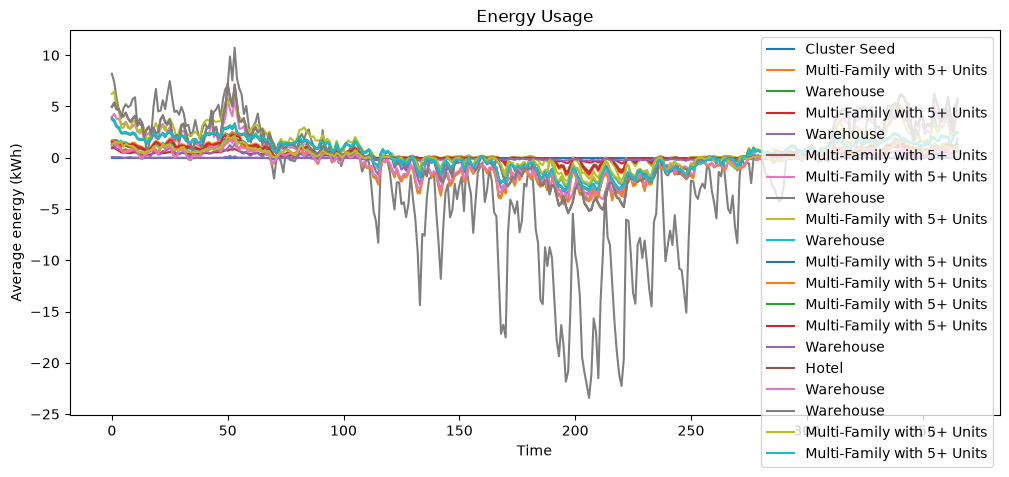

In [21]:
resampled_frames = [frame.resample("D").mean() for frame in frames]
building_loads = [building['net_load'].tolist() for building in resampled_frames]

building_types.insert(0, 'Cluster Seed')
building_distances.insert(0,0)
building_loads.insert(0, [0] * 366)

fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.tab10.colors  
for i, (load, type) in enumerate(zip(building_loads, building_types)):
    ax.plot(
        range(len(load)),
        load,
        color=colors[i % len(colors)],
        label=type
    )

ax.set_xlabel("Time")
ax.set_ylabel("Average energy (kWh)")
ax.set_title(f"Energy Usage")
ax.legend(title=None)

plt.legend()
plt.show()

# Run MILP Optimization on the Cluster

In [28]:
solution = solve_cluster(
    loads=building_loads,
    distances=building_distances,
    seed_idx=0,
    k_min=5,
    weight_peak=0.5,
    weight_net=0.5,
)
solution

{'total variables': 22,
 'total constraints': 735,
 'status': 'integer optimal solution',
 'objective': 0.05081380146463803,
 'best_bound': 0.05081380146463803,
 'selected': [0, 3, 4, 13, 14],
 'net_curve': array([ 3.66223858e+00,  3.82177789e+00,  3.30841932e+00,  3.01304522e+00,
         2.57443949e+00,  2.62015659e+00,  2.70273410e+00,  2.37386220e+00,
         2.36399828e+00,  2.52282899e+00,  2.51564831e+00,  1.94998220e+00,
         1.75439212e+00,  1.51022999e+00,  1.28623337e+00,  9.48146560e-01,
         1.10318764e+00,  1.58238486e+00,  2.37892210e+00,  2.83229732e+00,
         2.17579400e+00,  2.04423990e+00,  2.38086451e+00,  2.25021448e+00,
         2.81090545e+00,  3.24618126e+00,  3.07653371e+00,  2.31169782e+00,
         1.69109160e+00,  1.87682613e+00,  2.17854241e+00,  2.17047414e+00,
         1.80161125e+00,  1.71452178e+00,  1.48643939e+00,  1.43667595e+00,
         1.70469853e+00,  1.49664295e+00,  1.24537070e+00,  1.63739648e+00,
         2.03843173e+00,  2.409054

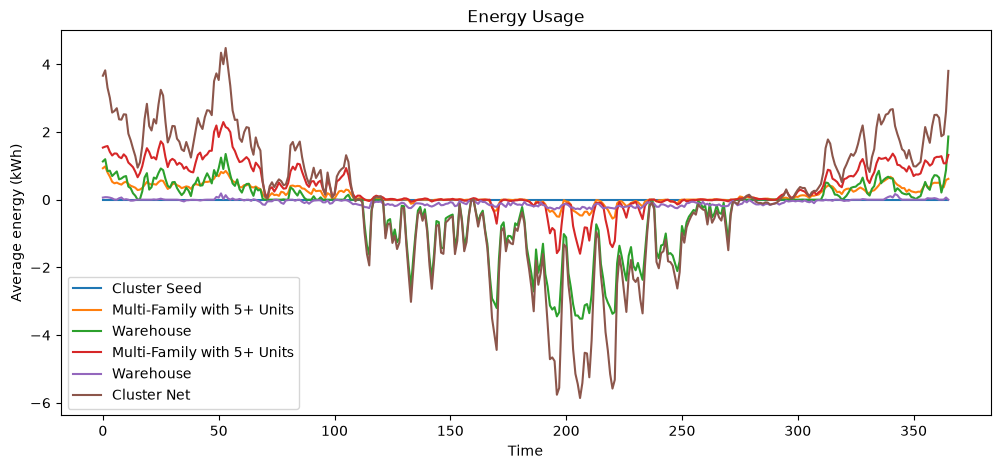

In [29]:
final_loads = [building_loads[i] for i in solution['selected']]
final_loads.append(solution['net_curve'])
final_types = [building_types[i] for i in solution['selected']]
final_types.append('Cluster Net')

fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.tab10.colors  
for i, (load, type) in enumerate(zip(final_loads, final_types)):
    ax.plot(
        range(len(load)),
        load,
        color=colors[i % len(colors)],
        label=type
    )

ax.set_xlabel("Time")
ax.set_ylabel("Average energy (kWh)")
ax.set_title(f"Energy Usage")
ax.legend(title=None)

plt.legend()
plt.show()

# Plot the Cluster

In [30]:
from shapely.geometry import LineString, Point
import folium

def plot_network_graph(
    network: nx.MultiDiGraph, 
    extra_layers: list
):
    """
    """
    edge_lines = []
    for u, v, data in network.edges(data=True):
        if 'geometry' in data:
            geom = data['geometry']
        else:
            # Build a LineString from node coordinates
            x1, y1 = network.nodes[u]['x'], network.nodes[u]['y']
            x2, y2 = network.nodes[v]['x'], network.nodes[v]['y']
            geom = LineString([(x1, y1), (x2, y2)])
        edge_lines.append({'u': u, 'v': v, 'geometry': geom})

    gdf_edges = gpd.GeoDataFrame(edge_lines, crs=network.graph['crs'])

    # Convert NetworkX nodes to a GeoDataFrame of Points
    node_points = []
    for n, data in network.nodes(data=True):
        node_points.append(
            {'node': n, 'geometry': Point(data['x'], data['y']), **data}
        )

    gdf_nodes = gpd.GeoDataFrame(node_points, crs=network.graph['crs'])

    # 3. Create the base interactive map using GeoPandas .explore()
    # m = base_gdf.explore(color='green', name='Base Map')

    m = gdf_edges.explore(color='blue', weight=2, name='Network Edges')
    m = gdf_nodes.explore(m=m, color='red', marker_kwds={'radius': 4}, name='Network Nodes')

    for name, gdf, color in (extra_layers or []):
        m = gdf.explore(m=m, color=color, name=name)

    # Fit to everything combined, since each explore() call re-fits to its own data
    all_bounds = [gdf_edges.to_crs(4326).total_bounds]
    all_bounds += [g.to_crs(4326).total_bounds for _, g, _ in (extra_layers or [])]
    minx = min(b[0] for b in all_bounds); miny = min(b[1] for b in all_bounds)
    maxx = max(b[2] for b in all_bounds); maxy = max(b[3] for b in all_bounds)
    m.fit_bounds([[miny, minx], [maxy, maxx]])

    folium.LayerControl().add_to(m)
    return m

In [31]:
cluster_indices = [i - 1 for i in solution['selected']]
final_cluster = cluster.reset_index(drop=True).copy()
final_cluster = final_cluster.iloc[cluster_indices[1:]]

final_seed = cropped_ghes[cropped_ghes['cluster'] == idx]

In [32]:
mst_subgraph, distance = create_cluster_subgraph(
    cluster_buildings=final_cluster,
    cluster_ghes=final_seed,
    G=network
)

In [33]:
m = plot_network_graph(
    mst_subgraph,
    extra_layers=[
        ('GHEs', final_seed, 'green'),
        ('Buildings', final_cluster, 'blue')
    ],
)
m